![Human in the loop](../diagrams/16-human-in-the-loop.png)

![Static breakpoints](../diagrams/15-static-breakpoints.png)

### Human In the Loop
Review
For human-in-the-loop, we often want to see our graph outputs as its running.

We laid the foundations for this with streaming.

Goals
Now, let's talk about the motivations for human-in-the-loop:

(1) Approval - We can interrupt our agent, surface state to a user, and allow the user to accept an action

(2) Debugging - We can rewind the graph to reproduce or avoid issues

(3) Editing - You can modify the state

LangGraph offers several ways to get or update agent state to support various human-in-the-loop workflows.

In [1]:
from dotenv import load_dotenv
load_dotenv()
import os

from langchain_openai import ChatOpenAI




llm=ChatOpenAI(model="gpt-4.1-mini", temperature=0)
result=llm.invoke("Hello")
result

AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 8, 'total_tokens': 17, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-mini-2025-04-14', 'system_fingerprint': 'fp_e7fa681843', 'id': 'chatcmpl-EeYrzF7nEL6U81EzFU6ZvkOJjqzlA', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a18b29-ce1f-7578-a79d-077d3a505875-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 9, 'total_tokens': 17, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [2]:
### Custom tools
def multiply(a: int, b: int) -> int:
    """Multiply a and b.

    Args:
        a: first int
        b: second int
    """
    return a * b

def add(a: int, b: int) -> int:
    """Adds a and b.

    Args:
        a: first int
        b: second int
    """
    return a + b

def divide(a: int, b: int) -> float:
    """Divide a by b.

    Args:
        a: first int
        b: second int
    """
    return a / b

tools=[add,multiply,divide]
tools



[<function __main__.add(a: int, b: int) -> int>,
 <function __main__.multiply(a: int, b: int) -> int>,
 <function __main__.divide(a: int, b: int) -> float>]

In [3]:
## Integrate tools with llm
llm_with_tools=llm.bind_tools(tools)
llm_with_tools

_ChatModelBinding(bound=ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7', 'langchain-openai': '1.7.3'}}, profile={'name': 'GPT-4.1 mini', 'release_date': '2025-04-14', 'last_updated': '2025-04-14', 'open_weights': False, 'max_input_tokens': 1047576, 'max_output_tokens': 32768, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True, 'mid_conversation_system_messages': True, 'mid_conversation_tools': False}, client=<openai.resources.chat.completions.completions.Completions object at 0x00000235C798E3C0>, async_client=<openai.resources.chat.completions.completions.Asy

### Part 1: Static breakpoints
`interrupt_before` / `interrupt_after` pause the graph **before/after a named node**. The LangGraph docs recommend them for *debugging* (stepping through a run). For real human-in-the-loop workflows use the dynamic `interrupt()` function shown in Part 2.

A checkpointer is required, because the paused state is saved and resumed by `thread_id`.

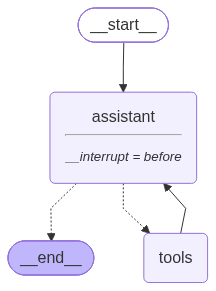

In [4]:
### Static breakpoints with `interrupt_before` (best for debugging)
from IPython.display import Image, display

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import MessagesState
from langgraph.graph import START, StateGraph
from langgraph.prebuilt import tools_condition, ToolNode
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage

## system Message
sys_msg = SystemMessage(content="You are a helpful assistant tasked with performing arithmetic on a set of inputs.")

## node definition
def assistant(state:MessagesState):
    return {"messages":[llm_with_tools.invoke([sys_msg] + state["messages"])]}

#Graph
builder=StateGraph(MessagesState)

## Define nodes: 
builder.add_node("assistant",assistant)
builder.add_node("tools",ToolNode(tools))

## Define the Edges

builder.add_edge(START,"assistant")
builder.add_conditional_edges(
    "assistant",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,

)
builder.add_edge("tools","assistant")

memory=MemorySaver()

### human in the loop
graph=builder.compile(interrupt_before=["assistant"],checkpointer=memory)

# Show
display(Image(graph.get_graph().draw_mermaid_png()))






In [5]:
thread={"configurable":{"thread_id":"123"}}
initial_input={"messages":HumanMessage(content="Multiply 2 and 3")}

In [6]:
for event in graph.stream(initial_input,thread,stream_mode="values"):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

Multiply 2 and 3


In [7]:
state=graph.get_state(thread)
state.next

('assistant',)

In [8]:
graph.get_state_history(thread)

<generator object Pregel.get_state_history at 0x00000235C82C97A0>

In [9]:
state

StateSnapshot(values={'messages': [HumanMessage(content='Multiply 2 and 3', additional_kwargs={}, response_metadata={}, id='c98a831e-86d5-4fd3-8877-e2015a03125a')]}, next=('assistant',), config={'configurable': {'thread_id': '123', 'checkpoint_ns': '', 'checkpoint_id': '1f1d41e2-6170-65c4-8000-e7bf786299db'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-30T04:55:37.834633+00:00', parent_config={'configurable': {'thread_id': '123', 'checkpoint_ns': '', 'checkpoint_id': '1f1d41e2-616e-6061-bfff-62a929456d7b'}}, tasks=(PregelTask(id='bc191be1-7818-9757-c527-ffcbb5948092', name='assistant', path=('__pregel_pull', 'assistant'), error=None, interrupts=(), state=None, result=None),), interrupts=())

In [10]:
## Continue the execution to Assistant
for event in graph.stream(None,thread,stream_mode="values"):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

Multiply 2 and 3


================================== Ai Message ==================================
Tool Calls:
  multiply (call_hsp80uCI3AYQt1j0PrQSnKcu)
 Call ID: call_hsp80uCI3AYQt1j0PrQSnKcu
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6


In [11]:
state=graph.get_state(thread)
state.next

('assistant',)

In [12]:
## Continue the execution of Assistant and then end
for event in graph.stream(None,thread,stream_mode="values"):
    event['messages'][-1].pretty_print()

================================= Tool Message =================================
Name: multiply

6


================================== Ai Message ==================================

The result of multiplying 2 and 3 is 6.


### Edit Human Feedback

In [13]:
initial_input={"messages":HumanMessage(content="Multiply 2 and 3")}

thread={"configurable":{"thread_id":"1"}}
for event in graph.stream(initial_input,thread,stream_mode="values"):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

Multiply 2 and 3


In [14]:
state=graph.get_state(thread)
state.next

('assistant',)

In [15]:
graph.update_state(thread,{"messages":[HumanMessage(content="No,please multiply 15 and 6")]})

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1d41e2-7833-6d1c-8001-e0485fccdab8'}}

In [16]:
new_state=graph.get_state(thread).values

for m in new_state['messages']:
    m.pretty_print()


================================ Human Message =================================

Multiply 2 and 3
================================ Human Message =================================

No,please multiply 15 and 6


In [17]:
for event in graph.stream(None, thread, stream_mode="values"):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

No,please multiply 15 and 6


================================== Ai Message ==================================
Tool Calls:
  multiply (call_MYimQJnweL9fsE26ruu0aMUT)
 Call ID: call_MYimQJnweL9fsE26ruu0aMUT
  Args:
    a: 15
    b: 6
================================= Tool Message =================================
Name: multiply

90


In [18]:
for event in graph.stream(None, thread, stream_mode="values"):
    event['messages'][-1].pretty_print()

================================= Tool Message =================================
Name: multiply

90


================================== Ai Message ==================================

The result of multiplying 15 and 6 is 90.


### Part 2: Dynamic interrupts with `interrupt()` and `Command(resume=...)` (recommended)

`interrupt(value)` is called **inside a node**. It pauses the graph, saves state through the checkpointer and hands `value` to the caller (under `"__interrupt__"`). When the caller resumes with `Command(resume=answer)` on the same `thread_id`, `interrupt()` returns `answer` and the node continues.

Rules to remember:
- On resume the node restarts from its first line, so code before `interrupt()` runs again (keep it side-effect free).
- Do not wrap `interrupt()` in a bare `try/except`.
- Pass only JSON-serializable values.

Below, a human approves (or redirects) every tool call before it is executed.

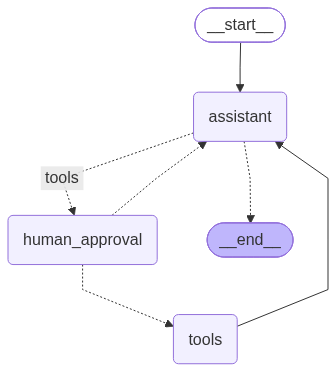

In [19]:
from typing import Literal
from langgraph.graph import END
from langgraph.types import Command, interrupt

sys_msg = SystemMessage(content="You are a helpful assistant tasked with performing arithmetic on a set of inputs.")

def assistant(state: MessagesState):
    return {"messages": [llm_with_tools.invoke([sys_msg] + state["messages"])]}

def human_approval(state: MessagesState) -> Command[Literal["tools", "assistant"]]:
    """Pause so a human can approve the tool call, or send new instructions instead."""
    tool_calls = state["messages"][-1].tool_calls
    decision = interrupt({"question": "Approve these tool calls? Reply 'approve' or type new instructions.",
                          "tool_calls": tool_calls})
    if decision == "approve":
        return Command(goto="tools")
    # Anything else is treated as feedback: send it back to the assistant
    # (the pending tool call is answered with a ToolMessage so the history stays valid)
    cancelled = [ToolMessage(content="Tool call cancelled by the user.", tool_call_id=t["id"]) for t in tool_calls]
    return Command(goto="assistant", update={"messages": cancelled + [HumanMessage(content=decision)]})

builder = StateGraph(MessagesState)
builder.add_node("assistant", assistant)
builder.add_node("human_approval", human_approval)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition, {"tools": "human_approval", END: END})
builder.add_edge("tools", "assistant")

graph = builder.compile(checkpointer=MemorySaver())
display(Image(graph.get_graph().draw_mermaid_png()))

In [20]:
thread = {"configurable": {"thread_id": "approve-1"}}

# Runs until interrupt() is hit
result = graph.invoke({"messages": [HumanMessage(content="Multiply 2 and 3")]}, thread)
print(result["__interrupt__"])

[Interrupt(value={'question': "Approve these tool calls? Reply 'approve' or type new instructions.", 'tool_calls': [{'name': 'multiply', 'args': {'a': 2, 'b': 3}, 'id': 'call_Rdqq7WtaUqETQW6vipECoV80', 'type': 'tool_call'}]}, id='a3e06b48d033b8f36edf34eb7b4fc15b', response_schema=None)]


The graph is paused inside `human_approval`. Resume it by passing the human's answer with `Command(resume=...)`:

In [21]:
result = graph.invoke(Command(resume="approve"), thread)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Multiply 2 and 3
================================== Ai Message ==================================
Tool Calls:
  multiply (call_Rdqq7WtaUqETQW6vipECoV80)
 Call ID: call_Rdqq7WtaUqETQW6vipECoV80
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6
================================== Ai Message ==================================

The result of multiplying 2 and 3 is 6.


#### Rejecting and redirecting
This time the human does not approve, and says what they want instead.

In [22]:
thread = {"configurable": {"thread_id": "approve-2"}}

result = graph.invoke({"messages": [HumanMessage(content="Multiply 2 and 3")]}, thread)
print(result["__interrupt__"])

result = graph.invoke(Command(resume="No, please multiply 15 and 6"), thread)
# the assistant now proposes a new tool call, which interrupts again
print(result["__interrupt__"])

result = graph.invoke(Command(resume="approve"), thread)
for m in result["messages"]:
    m.pretty_print()

[Interrupt(value={'question': "Approve these tool calls? Reply 'approve' or type new instructions.", 'tool_calls': [{'name': 'multiply', 'args': {'a': 2, 'b': 3}, 'id': 'call_2q1yjXd2iQr3Li3osEIu9Aqw', 'type': 'tool_call'}]}, id='05ad988be1970cfb83de2f8f6de6d410', response_schema=None)]


[Interrupt(value={'question': "Approve these tool calls? Reply 'approve' or type new instructions.", 'tool_calls': [{'name': 'multiply', 'args': {'a': 15, 'b': 6}, 'id': 'call_sH8BS15TAOVQY5GPUFzNejnO', 'type': 'tool_call'}]}, id='c1da92249365d3f5a1f0efdb60f9a928', response_schema=None)]


================================ Human Message =================================

Multiply 2 and 3
================================== Ai Message ==================================
Tool Calls:
  multiply (call_2q1yjXd2iQr3Li3osEIu9Aqw)
 Call ID: call_2q1yjXd2iQr3Li3osEIu9Aqw
  Args:
    a: 2
    b: 3
================================= Tool Message =================================

Tool call cancelled by the user.
================================ Human Message =================================

No, please multiply 15 and 6
================================== Ai Message ==================================
Tool Calls:
  multiply (call_sH8BS15TAOVQY5GPUFzNejnO)
 Call ID: call_sH8BS15TAOVQY5GPUFzNejnO
  Args:
    a: 15
    b: 6
================================= Tool Message =================================
Name: multiply

90
================================== Ai Message ==================================

The result of multiplying 15 and 6 is 90.
